In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LogLinearEnergyPT, LogLinearEnergyGrad
from raddest.transfer import NegLogPlus

## Mock data

The same log-linear model with heteroscedastic errors as in `fit_loglinear.ipynb`.

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)
y = 10 ** (k * np.log10(x) + b + np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)
y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

In [ ]:
# the energy permutation test compares against the observed 2D sample
# directly; a 2000-point sub-sample keeps each grid point affordable
idx = np.random.choice(N, 2000, replace=False)
x_obs_fit, y_obs_fit = x_obs[idx], y_obs[idx]

Text(0, 0.5, 'y')

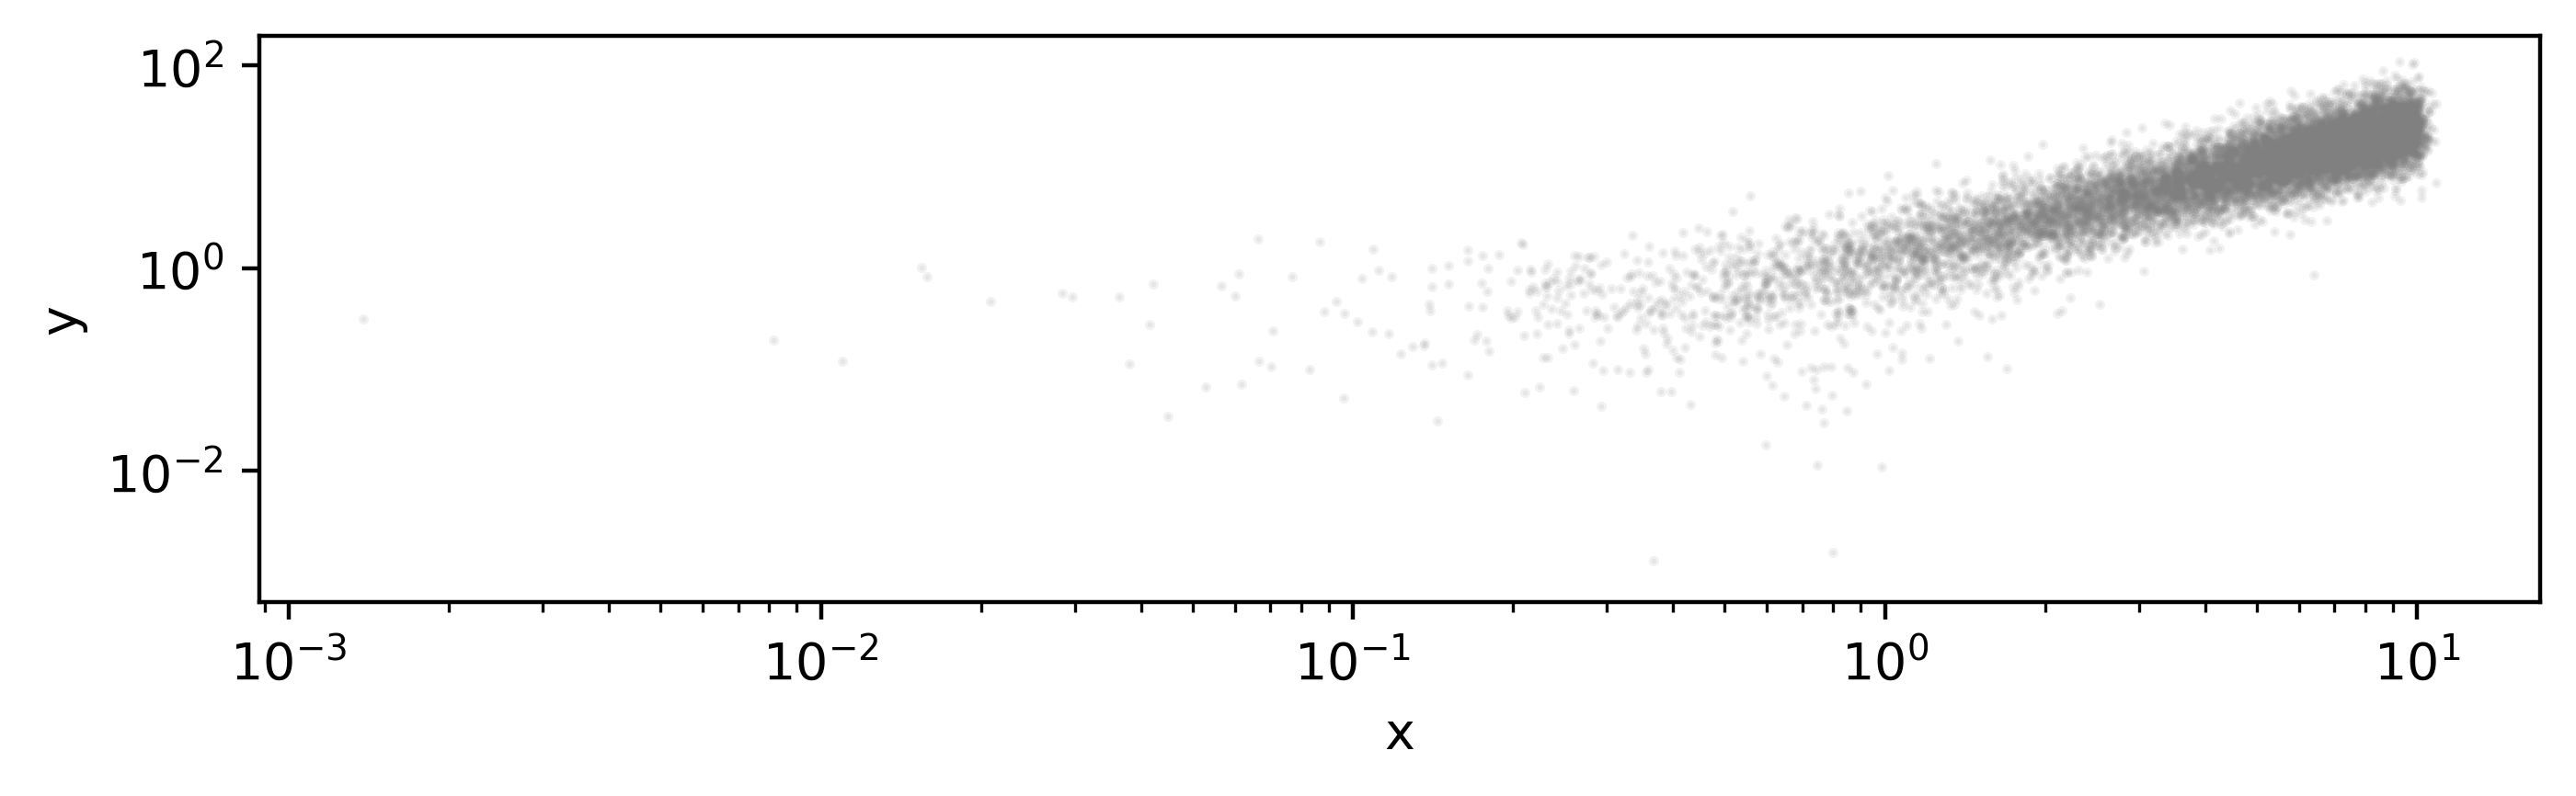

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x')
plt.ylabel('y')

## Fit p(x, x_err) and p(y, y_err)

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

2026-11-24 20:10:36.816556: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:52,  5.99s/it]

  8%|▊         | 8/100 [00:06<00:51,  1.79it/s]

 15%|█▌        | 15/100 [00:06<00:21,  3.97it/s]

 22%|██▏       | 22/100 [00:06<00:11,  6.84it/s]

... (11 outputs left out)

step 0: loss 1.4481308460235596


step 10: loss 1.428924798965454
step 20: loss 1.430019736289978


step 30: loss 1.4316834211349487
step 40: loss 1.428908348083496


step 50: loss 1.427069067955017
step 60: loss 1.426827311515808


In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:03,  5.49s/it]

  8%|▊         | 8/100 [00:05<00:47,  1.95it/s]

 15%|█▌        | 15/100 [00:05<00:19,  4.32it/s]

 23%|██▎       | 23/100 [00:05<00:09,  7.86it/s]

 30%|███       | 30/100 [00:05<00:05, 11.76it/s]

... (11 outputs left out)

step 0: loss 2.653981924057007
step 10: loss 2.6203231811523438


step 20: loss 2.6076672077178955
step 30: loss 2.601651906967163


step 40: loss 2.597437858581543
step 50: loss 2.5952179431915283


step 60: loss 2.593296766281128


## Energy-test grid search (numpy backend)

`LogLinearEnergyPT` weights the zoom-in grid with the p-value of a permutation energy-distance test between the synthetic and observed 2D samples. The numpy backend evaluates one grid point per worker process. Each point costs `O((N + M)^2 * permutations)`, so this example uses a coarse grid, a small synthetic sample and fewer permutations than the defaults.

In [ ]:
params_list = [
    np.linspace(0.5, 2.0, 5),
    np.linspace(-0.5, 0.6, 5),
    np.linspace(0.05, 0.4, 3),
]

fit_args = dict(params_list=params_list, N=400, max_i=1, refine=True,
                gen_new_grid_refine_kwargs={'n': 4}, verbose=True)

regressor_pt = LogLinearEnergyPT(xflow, yflow, permutations=30)
%time params_mean, params_std, res_arr = regressor_pt.fit(x_obs_fit, y_obs_fit, **fit_args)
print('energy-PT fitted:', *params_mean)
print('Truth:', k, b, sig)


/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.250 +/- 0.530
b: 0.050 +/- 0.389
sig: 0.225 +/- 0.143


----
k: 1.250 +/- 0.677
b: 0.050 +/- 0.496
sig: 0.255 +/- 0.163
max iteration reached


CPU times: user 5.44 s, sys: 1.18 s, total: 6.62 s
Wall time: 5min 1s
energy-PT fitted: 1.2431774749903344 0.05500318500708806 0.29212866133697196
Truth: 1.3 0.1 0.2


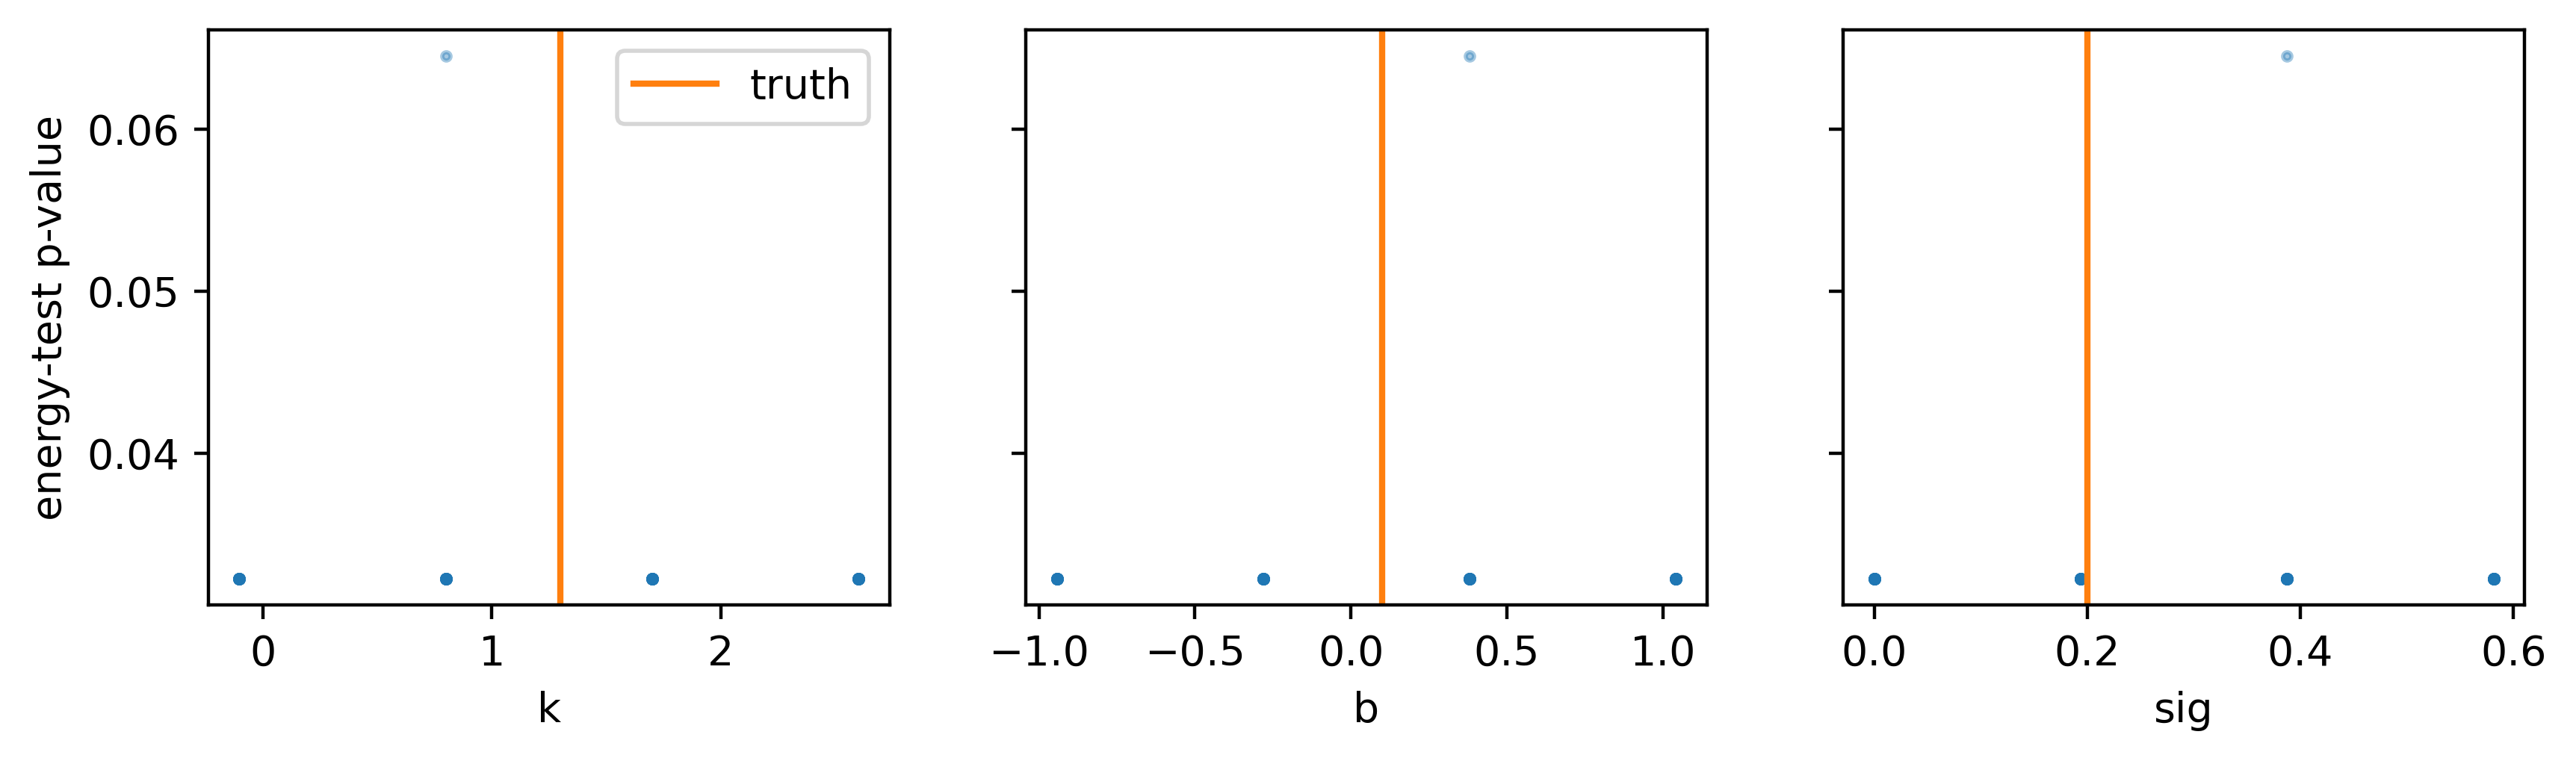

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.5), dpi=400, sharey=True)
for i, ax in enumerate(axes):
    ax.scatter(res_arr[:, i], res_arr[:, 4], s=4, alpha=0.4)
    ax.axvline([k, b, sig][i], color='C1', label='truth')
    ax.set_xlabel(['k', 'b', 'sig'][i])
axes[0].set_ylabel('energy-test p-value')
axes[0].legend()

## The same fit on the jax grid backend

With `backend='jax'` the whole grid is evaluated in a single jax process: the permutation tests run as batched matrix products on the GPU instead of one numpy loop per worker. The numerical recipe (grid, zoom-in, weighting) is identical; only the evaluation engine changes.

In [ ]:
regressor_pt_jax = LogLinearEnergyPT(xflow, yflow, permutations=30, backend='jax')
%time params_mean_jax, params_std_jax, res_arr_jax = regressor_pt_jax.fit(x_obs_fit, y_obs_fit, **fit_args)
print('energy-PT (jax) fitted:', *params_mean_jax)
print('Truth:', k, b, sig)


----
k: 1.250 +/- 0.530
b: 0.050 +/- 0.389
sig: 0.225 +/- 0.143


----
k: 1.250 +/- 0.677
b: 0.050 +/- 0.496
sig: 0.255 +/- 0.163
max iteration reached


CPU times: user 2.33 s, sys: 144 ms, total: 2.48 s
Wall time: 2.62 s
energy-PT (jax) fitted: 1.2499999999999982 0.05000000000000012 0.2907030125761345
Truth: 1.3 0.1 0.2


## Gradient descent on the energy distance

`LogLinearEnergyGrad` skips grid search altogether: the synthetic sample is generated differentiably from the parameters and the energy distance to the observed sample is minimized with adam.

In [ ]:
regressor_grad = LogLinearEnergyGrad(xflow, yflow)
%time params_hat, loss_history = regressor_grad.fit(x_obs_fit, y_obs_fit, params_0=np.array([1.0, 0.0, 0.3]), N=500, lr=5e-2, n_step=3000, check_per_step=100, seed=0)
print('energy-grad fitted:', *params_hat)
print('Truth:', k, b, sig)

CPU times: user 3.95 s, sys: 452 ms, total: 4.4 s
Wall time: 4.2 s
energy-grad fitted: 1.3115631 0.100253046 0.210665
Truth: 1.3 0.1 0.2


Text(0, 0.5, 'energy distance')

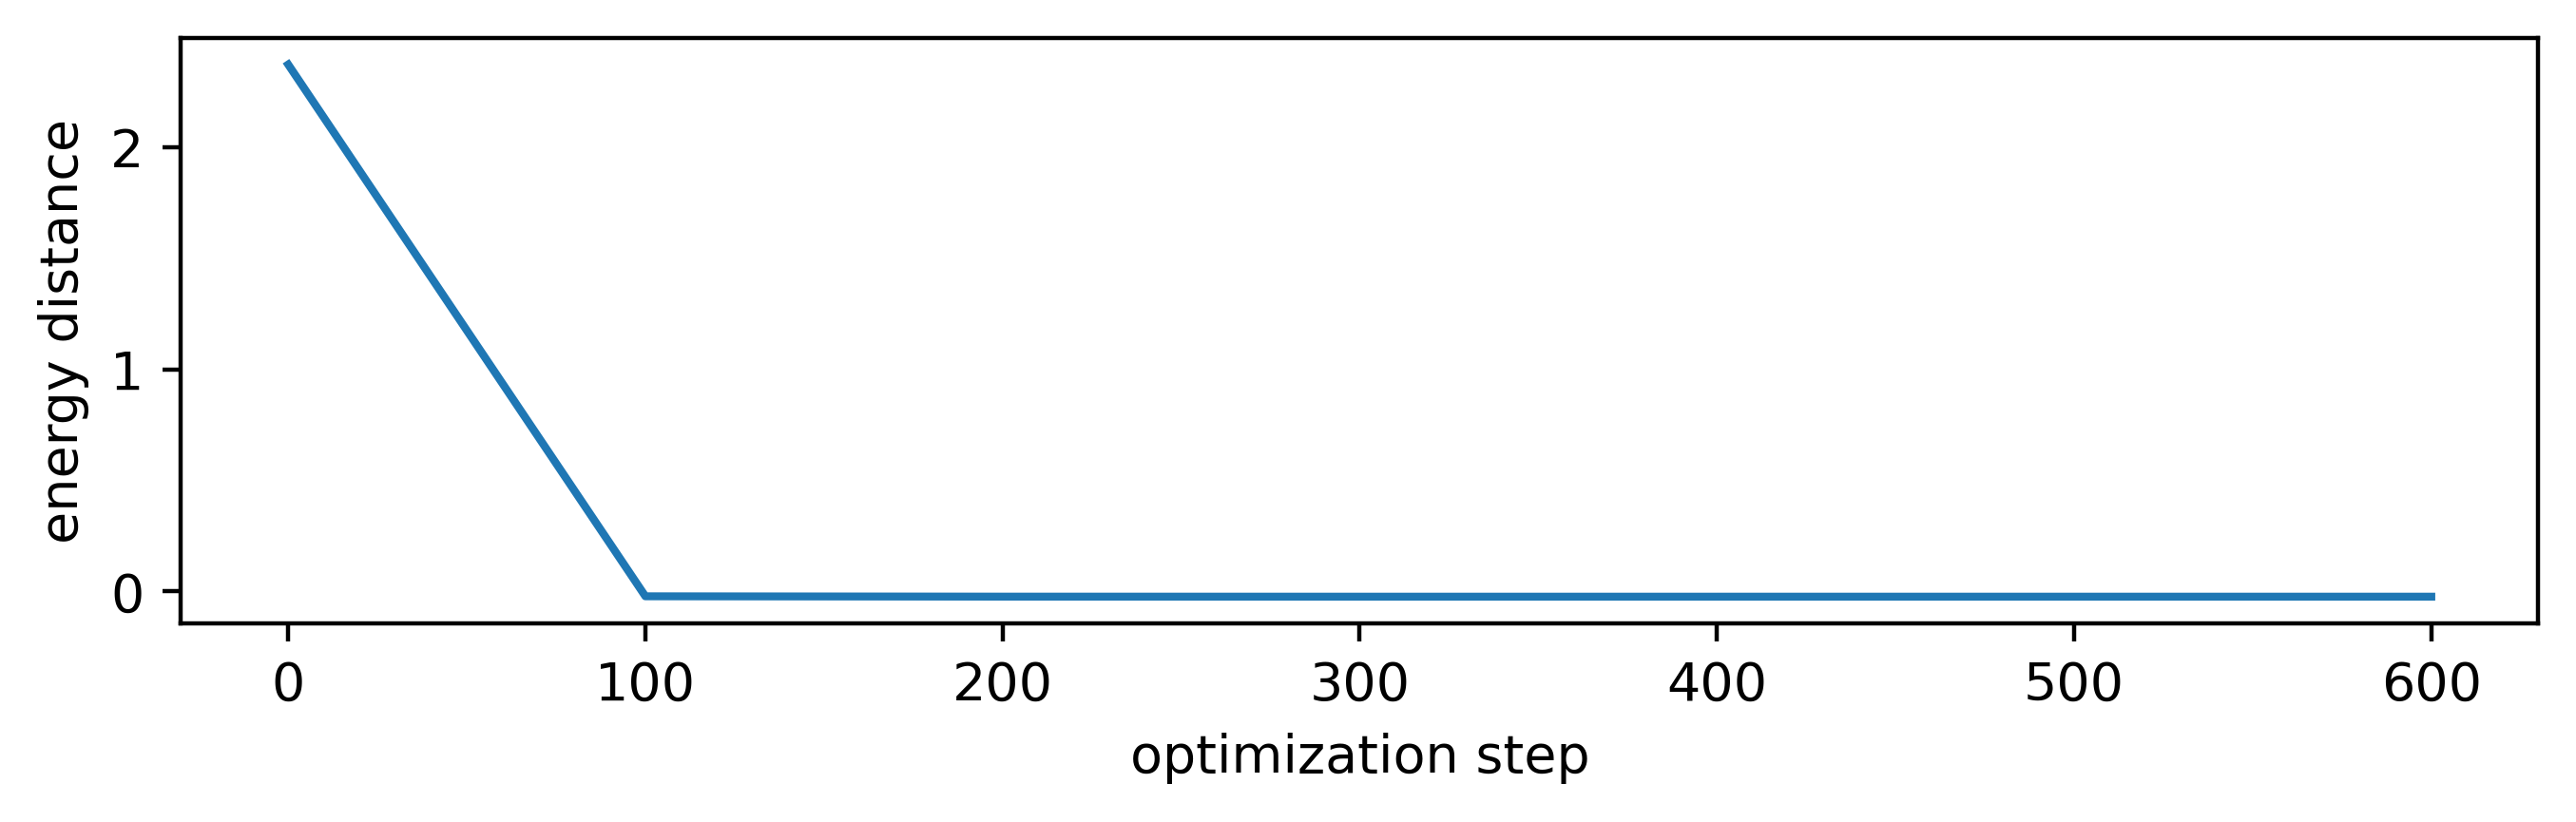

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)
plt.plot(np.arange(len(loss_history)) * 100, loss_history)
plt.xlabel('optimization step')
plt.ylabel('energy distance')

## Goodness of fit

The energy test itself: a good parameter set gives a large p-value, a bad one the smallest possible.

In [ ]:
# the test is powerful: with thousands of points it detects even the
# slight misfit of the fitted parameters, so compare at the true
# parameters instead — a model that generated the data cannot be
# rejected, while clearly wrong parameters hit the p-value floor
params_true = np.array([k, b, sig])
_, p_true = regressor_pt.energy_test(params_true, x_obs, y_obs, N=500, M=1000, permutations=100)
_, p_bad = regressor_pt.energy_test(np.array([3.0, 1.0, 0.5]), x_obs, y_obs, N=500, M=1000, permutations=100)
print(f'p-value at the true parameters: {p_true:.3f}')
print(f'p-value at clearly wrong parameters: {p_bad:.3f}')


p-value at the true parameters: 0.267
p-value at clearly wrong parameters: 0.010


Text(0, 0.5, 'y')

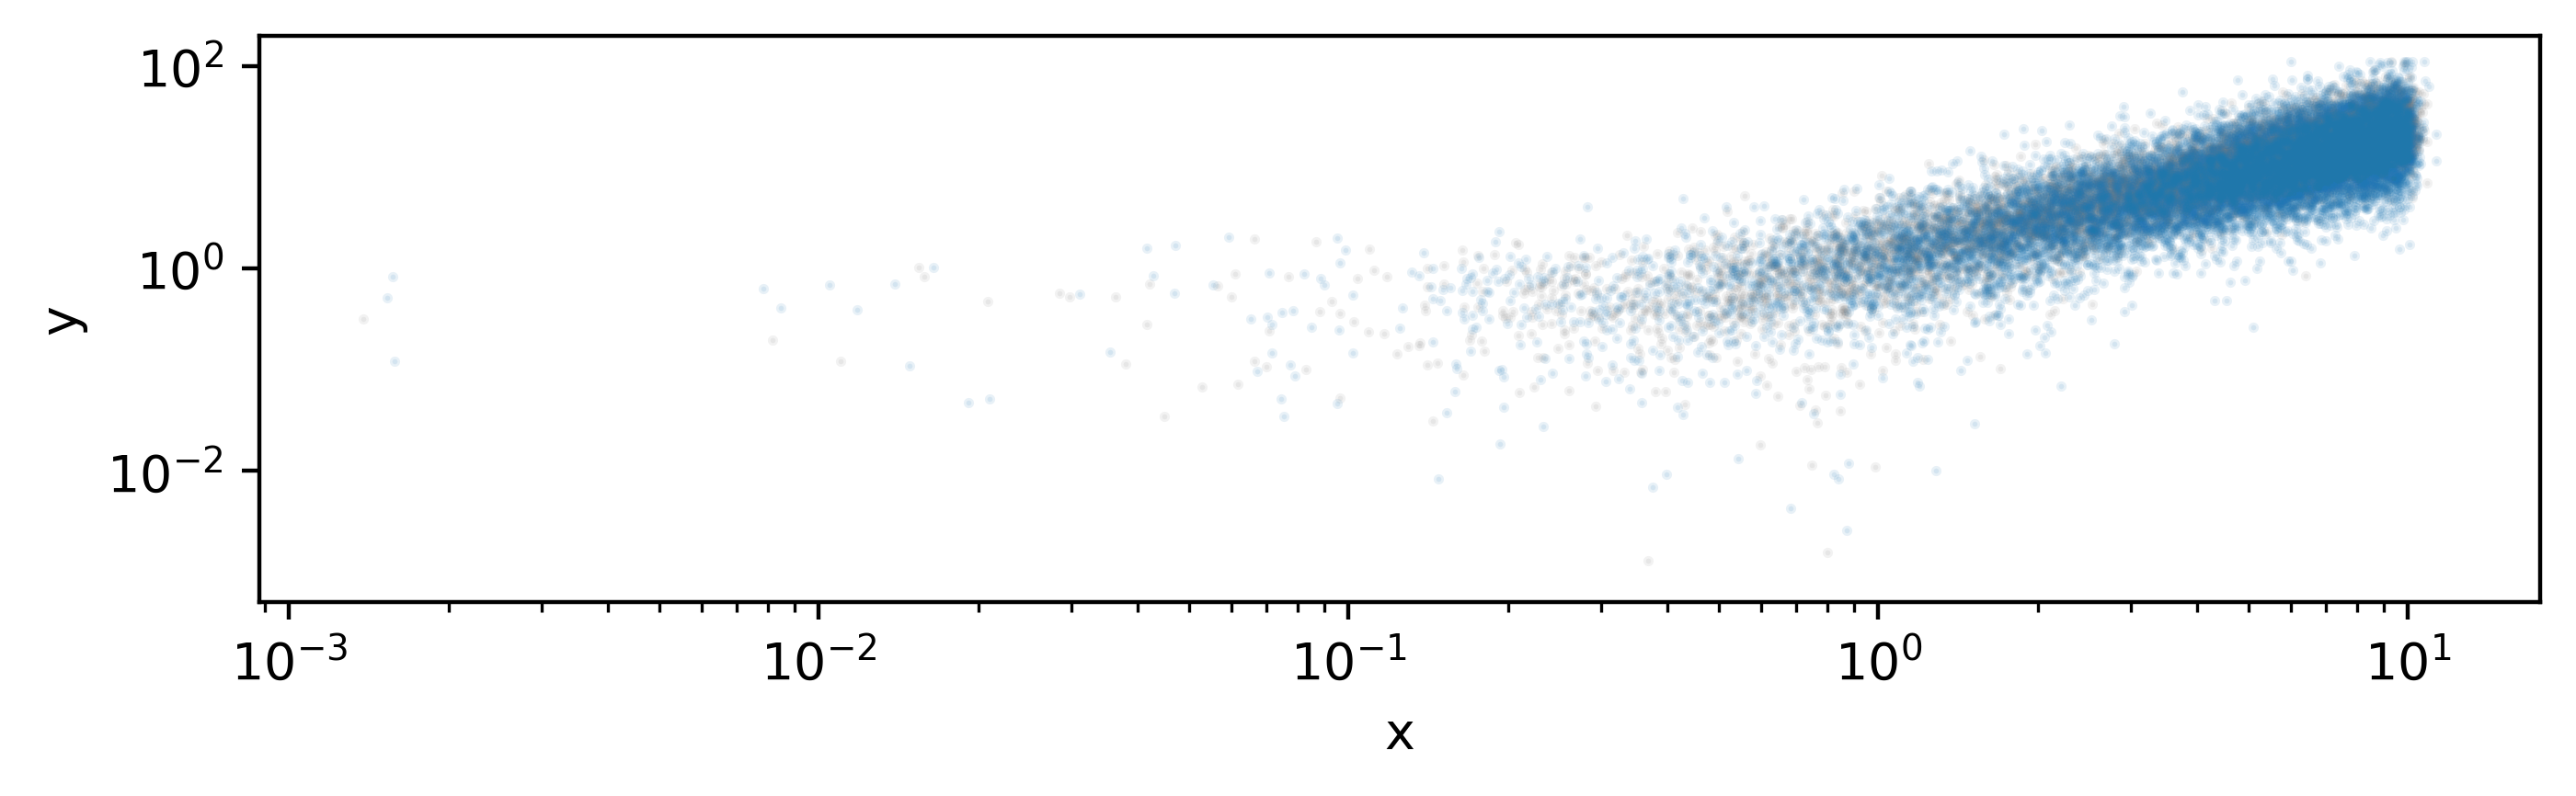

In [ ]:
params_fit = np.asarray(params_mean_jax)
x_obs_gen, y_obs_gen, _, _, x_gen, _ = regressor_pt.sample(params_fit, N=10000)

plt.figure(figsize=(8, 2), dpi=400)
plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.1)
plt.scatter(x_obs_gen, y_obs_gen, s=1, color='C0', alpha=0.1)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('x')
plt.ylabel('y')
